In [2]:
import pandas as pd
import numpy as np
url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
births = pd.read_csv(url)
births_raw = births.copy()
print("First Five Rows:")
print(births.head())
print("\nShape of Dataset:")
print(births.shape)
print("\nData Types:")
print(births.dtypes)
print("\nMissing Values:")
print(births.isnull().sum())

First Five Rows:
   year  month  day gender  births
0  1969      1  1.0      F    4046
1  1969      1  1.0      M    4440
2  1969      1  2.0      F    4454
3  1969      1  2.0      M    4548
4  1969      1  3.0      F    4548

Shape of Dataset:
(15547, 5)

Data Types:
year        int64
month       int64
day       float64
gender        str
births      int64
dtype: object

Missing Values:
year        0
month       0
day       480
gender      0
births      0
dtype: int64


In [4]:
births_raw['decade'] = 10 * (births_raw['year'] // 10)
births_by_decade = births_raw.pivot_table(
    values='births',
    index='decade',
    columns='gender',
    aggfunc='sum'
)
verification = births_by_decade['M'] > births_by_decade['F']

print("Male births outnumber female births in every decade:")
print(verification)
print("\nResult:", verification.all())


Male births outnumber female births in every decade:
decade
1960    True
1970    True
1980    True
1990    True
2000    True
dtype: bool

Result: True


In [5]:
births_by_decade['M_F_Ratio'] = births_by_decade['M'] / births_by_decade['F']
births_by_decade['Percent_Excess'] = (
    (births_by_decade['M'] - births_by_decade['F'])
    / births_by_decade['F']
) * 100
print(births_by_decade[['M_F_Ratio', 'Percent_Excess']])

gender  M_F_Ratio  Percent_Excess
decade                           
1960     1.052997        5.299738
1970     1.052787        5.278676
1980     1.050960        5.096030
1990     1.048312        4.831239
2000     1.048116        4.811587


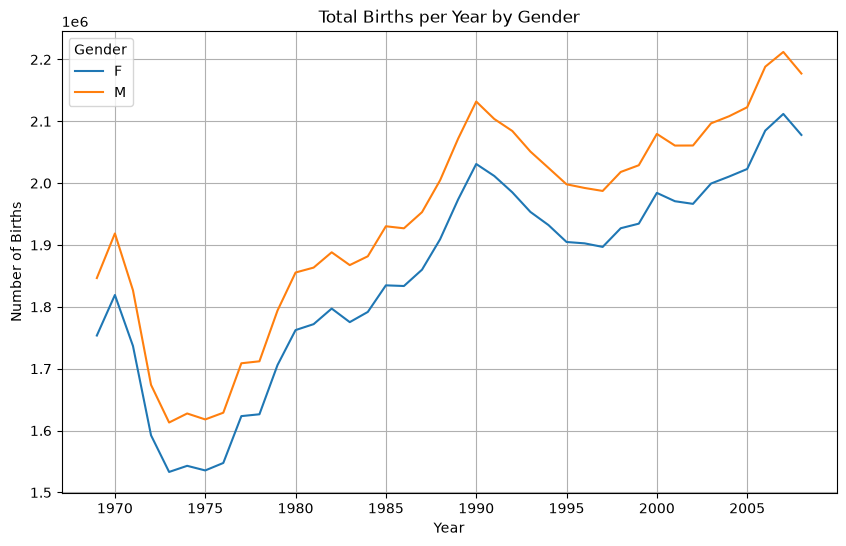

In [7]:
import matplotlib.pyplot as plt
births_by_year = births_raw.pivot_table(
    values='births',
    index='year',
    columns='gender',
    aggfunc='sum'
)
births_by_year.plot(figsize=(10, 6))

plt.title('Total Births per Year by Gender')
plt.xlabel('Year')
plt.ylabel('Number of Births')
plt.legend(title='Gender')
plt.grid(True)

plt.show()

In [8]:
Q1, Q2, Q3 = np.percentile(births['births'], [25, 50, 75])  
mu = Q2
sig = 0.74 * (Q3 - Q1)
print("Q1 =", Q1)
print("Median (mu) =", mu)
print("Q3 =", Q3)
print("Robust Std Dev (sig) =", sig)

Q1 = 4358.0
Median (mu) = 4814.0
Q3 = 5289.5
Robust Std Dev (sig) = 689.31


In [9]:
original_rows = len(births)
births_clean = births.query('(births > @mu - 5 * @sig) & (births < @mu + 5 * @sig)')
removed_rows = original_rows - len(births_clean)
print("Rows removed:", removed_rows)
print("Remaining rows:", len(births_clean))

Rows removed: 937
Remaining rows: 14610


In [10]:
# Convert day column to integer
births_clean['day'] = births_clean['day'].astype(int)

print(births_clean['day'].dtype)

int64


In [12]:
# Pivot table result
pivot_table_result = births_raw.pivot_table(
    values='births',
    index='decade',
    columns='gender',
    aggfunc='sum'
)
groupby_result = births_raw.groupby(
    ['decade', 'gender']
)['births'].sum().unstack()
print(groupby_result)
print("Tables Match:", pivot_table_result.equals(groupby_result))

gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428
Tables Match: True


In [17]:

%timeit births_raw.pivot_table(values='births',index='decade',columns='gender',aggfunc='sum')
# Time groupby
%timeit births_raw.groupby(['decade', 'gender'])['births'].sum().unstack()

6.21 ms ± 182 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
3.3 ms ± 66.9 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


Five dates with lowest average births:
              births
2012-12-25  3844.450
2012-01-01  4009.225
2012-12-24  4126.250
2012-01-02  4247.400
2012-07-04  4335.325


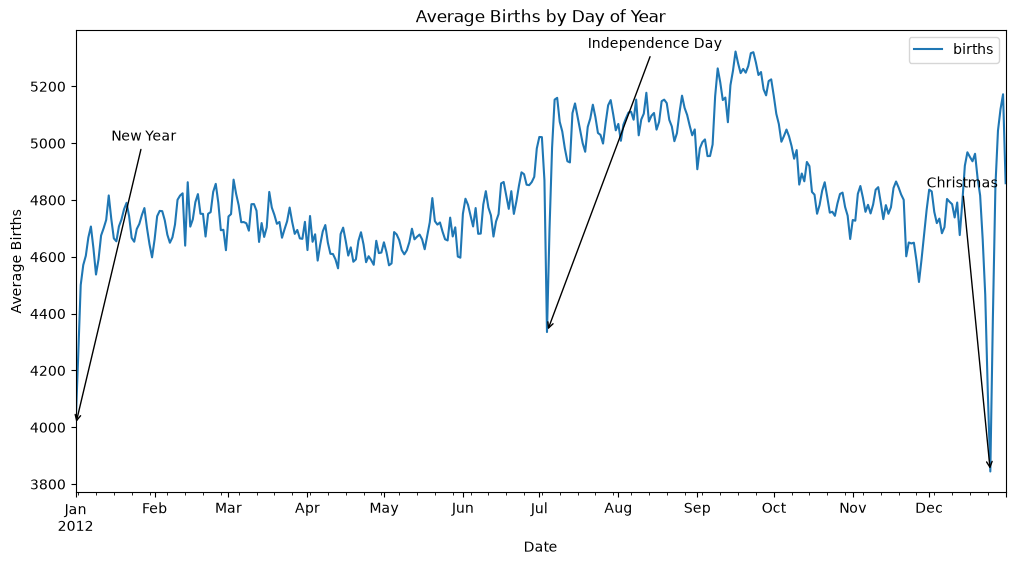

In [24]:
import datetime
# 1. Filter out invalid days if any, then create a Date column
births_clean = births_clean[births_clean['day'] != 99].copy()
births_clean['datetime'] = pd.to_datetime(
    births_clean['year'].astype(str) + '-' + 
    births_clean['month'].astype(str) + '-' + 
    births_clean['day'].astype(str),
    format='%Y-%m-%d',
    errors='coerce'
)
# 2. Extract Month and Day to group by day of the year
births_by_date = births_clean.pivot_table(
    'births', 
    index=[births_clean['datetime'].dt.month, births_clean['datetime'].dt.day]
)
# 3. Set a dummy non-leap year (2012) using standard datetime
births_by_date.index = [datetime.datetime(2012, int(month), int(day)) for (month, day) in births_by_date.index]
# Five dates with lowest average births
lowest_births = births_by_date.nsmallest(5, 'births')
print("Five dates with lowest average births:")
print(lowest_births)
# Plotting
fig, ax = plt.subplots(figsize=(12, 6))
births_by_date.plot(ax=ax)
# Annotate major holiday dips
ax.annotate('New Year', xy=('2012-01-01', births_by_date.loc['2012-01-01', 'births']),
            xytext=('2012-01-15', births_by_date.loc['2012-01-01', 'births'] + 1000),
            arrowprops=dict(arrowstyle='->'))
ax.annotate('Independence Day', xy=('2012-07-04', births_by_date.loc['2012-07-04', 'births']),
            xytext=('2012-07-20', births_by_date.loc['2012-07-04', 'births'] + 1000),
            arrowprops=dict(arrowstyle='->'))
ax.annotate('Christmas', xy=('2012-12-25', births_by_date.loc['2012-12-25', 'births']),
            xytext=('2012-11-30', births_by_date.loc['2012-12-25', 'births'] + 1000),
            arrowprops=dict(arrowstyle='->'))
plt.title('Average Births by Day of Year')
plt.xlabel('Date')
plt.ylabel('Average Births')
plt.show()